# Figure 3 - Ice-Free timing and IPO correlation

In [1]:
import xarray as xr
import matplotlib.pyplot as plt
import numpy as np
import scipy.stats as stats
from statsmodels.stats.multitest import multipletests
import glob
import re

In [2]:
model_names = [
    'ACCESS-ESM1-5', 'CESM2-LENS', 'CanESM5', 'EC-Earth3', 
    'MIROC6', 'MPI-ESM1-2-LR', 'CanESM2', 'CESM1'
]

model_years = {
    'CanESM5':[1850,2100], 'CESM2-LENS':[1850,2100], 'ACCESS-ESM1-5':[1850,2100], 
    'MPI-ESM1-2-LR':[1850,2100], 'MIROC6':[1850,2100], 'EC-Earth3':[1850,2100], 
    'CanESM2':[1950,2100], 'CESM1':[1920,2100],
}

## Load Sea Ice Extent (SIE) data

In [3]:
#load the September SIE
All_SIE = xr.open_dataset('/glade/work/cwpowell/ice-free/sea_ice_data/All_Model_September_SIE.nc')

sep_SIE = {}

for model_name in model_names:
    #drop NA members caused by models with different member names
    sep_SIE[model_name] = All_SIE[model_name].dropna(dim='member', how='all').dropna(dim='time', how='all')
    
#compute a rolling 11-year average
sep_SIE_11yr = {}

for model_name in model_names:
    sep_SIE_11yr[model_name] = sep_SIE[model_name].rolling(time=11, center=True).mean()

In [4]:
ens_IF = {}
for model_name in ['ACCESS-ESM1-5',
     'CanESM5', 'CESM2-LENS', 'EC-Earth3', 'MIROC6', 'MPI-ESM1-2-LR',
     'CanESM2', 'CESM1']:
    start_yr_LE = int(sep_SIE_11yr[model_name]['time'].where(
                    (sep_SIE_11yr[model_name].mean('member') - 4.7) < 0).min('time'))
    end_yr_LE = int(sep_SIE_11yr[model_name]['time'].where(
                    (sep_SIE_11yr[model_name].mean('member') - 1) < 0).min('time'))
    ens_IF[model_name] = end_yr_LE - start_yr_LE

## Load the IPO data

In [5]:
# #load the IPO derived from the TPI index
# IPO_models = {}

# base_path = '/glade/work/cwpowell/low-freq-trajectories/SST_for_IPO/IPO_per_Screen_Deser/'
# file_name = '_11yr_annual_av_TPI.nc'

# for model_name in model_names:
#     if model_name == 'CESM2-LENS':
#         temp = xr.open_dataarray(base_path+'CESM2-LENS'+file_name)
        
#         IPO_models[model_name] = temp.sel(
#             member=sep_SIE_11yr[model_name]['member'])
    
#     elif model_name in ['CanESM2', 'CESM1', 'GFDL-ESM2M']:
#         temp = xr.open_dataarray(base_path+model_name+file_name)
        
#         temp['member'] = [f'r{mem_}i1p1' for mem_ in temp['member'].values]
            
#         IPO_models[model_name] = temp.sortby('member')
    
#     else:
#         IPO_models[model_name] = xr.open_dataarray(base_path+model_name+file_name)

# #drop CanESM5 r1i1p1f1 as no historical SIE data
# IPO_models['CanESM5'] = IPO_models['CanESM5'].drop_sel(member='r1i1p1f1')

In [5]:
path = ('/glade/work/cwpowell/low-freq-trajectories/SST_for_IPO/'
        'IPO_per_Screen_Deser/IPO_11yr_annual_av_TPI_all_models.nc')

IPO_models = {model_name: xr.open_dataarray(path, group=model_name)
              for model_name in model_names}

In [6]:
#look at the backward IPO phases from a running 11-year mean IF year
IPO_backward = {} #first IF year
IPO_backward_mean = {} #IF year of 11-year running mean
IPO_backward_binary = {}
for model_name in model_names:

    IPO_backward_mems = []
    IPO_backward_mean_mems = []
    IPO_backward_binary_mems = []
    
    SIE_model = sep_SIE[model_name]
    SIE_model_mean = sep_SIE_11yr[model_name]
    IPO_model = IPO_models[model_name]

    for mem_ in SIE_model['member']:
        
        try:
            SIE_mem = SIE_model.sel(member=mem_)
            SIE_mem_mean = SIE_model_mean.sel(member=mem_)
            IPO_mem = IPO_model.sel(member=mem_)
        except KeyError:
            print(model_name, str(mem_.values), 'not available for both SIE and IPO')
            continue
            
        #find IF year, append IPO values for 50 years beforehand, reindex to -50 to 0
        IF_yr = int(SIE_mem['time'].where((SIE_mem - 1) < 0).min())
        IPO_backward_tmp = IPO_mem.sel(year=slice(IF_yr-50,IF_yr+10))
        IPO_backward_tmp['year'] = np.arange(-50,11)
        IPO_backward_mems.append(IPO_backward_tmp)

        #find IF year of 11-year running mean 
        IF_yr_mean = int(SIE_mem_mean['time'].where((SIE_mem_mean - 1) < 0).min())
        IPO_backward_mean_tmp = IPO_mem.sel(year=slice(IF_yr_mean-50,IF_yr_mean+10))
        IPO_backward_mean_tmp['year'] = np.arange(-50,11)
        IPO_backward_mean_mems.append(IPO_backward_mean_tmp)

        IPO_backward_binary_mems.append(xr.where(IPO_backward_tmp >= 0.9, 1,
            xr.where(IPO_backward_tmp <= -0.9, -1, 0)))

    IPO_backward_mems_xr = xr.concat((IPO_backward_mems),dim='member')
    IPO_backward[model_name] = IPO_backward_mems_xr

    IPO_backward_mean_mems_xr = xr.concat((IPO_backward_mean_mems),dim='member')
    IPO_backward_mean[model_name] = IPO_backward_mean_mems_xr

    IPO_backward_mems_binary_xr = xr.concat((IPO_backward_binary_mems),dim='member')
    IPO_backward_binary[model_name] = IPO_backward_mems_binary_xr

CanESM5 r1i1p1f1 not available for both SIE and IPO
EC-Earth3 r11i1p1f1 not available for both SIE and IPO
EC-Earth3 r13i1p1f1 not available for both SIE and IPO
EC-Earth3 r15i1p1f1 not available for both SIE and IPO
EC-Earth3 r1i1p1f1 not available for both SIE and IPO
EC-Earth3 r4i1p1f1 not available for both SIE and IPO
EC-Earth3 r6i1p1f1 not available for both SIE and IPO


## Group the IF years (11-year mean) by time from ensemble mean

In [8]:
#use backward IPO phases and also get the IF years
IF_rel_yrs = {}
IF_rel_mean_yrs = {}

for model_name in model_names:
    
    IF_rel_yrs_mems = []
    SIE_model = sep_SIE[model_name]

    IF_rel_mean_yrs_mems = []
    SIE_model_mean = sep_SIE_11yr[model_name]

    #find the ensemble mean IF year
    SIE_ens = SIE_model.mean('member')
    IF_yr_ens = int(SIE_ens['time'].where((SIE_ens - 1) < 0).min())

    SIE_mean_ens = SIE_model_mean.mean('member')
    IF_yr_mean_ens = int(SIE_mean_ens['time'].where((SIE_mean_ens - 1) < 0).min())

    for mem_ in SIE_model['member']:
        
        SIE_mem = SIE_model.sel(member=mem_)
        SIE_mean_mem = SIE_model_mean.sel(member=mem_)
        
        #find IF year for individual member
        IF_yr = int(SIE_mem['time'].where((SIE_mem - 1) < 0).min())
        IF_mean_yr = int(SIE_mean_mem['time'].where((SIE_mean_mem - 1) < 0).min())
               
        IF_rel_yrs_mems.append(IF_yr - IF_yr_ens)
        IF_rel_mean_yrs_mems.append(IF_mean_yr - IF_yr_mean_ens)

    IF_rel_yrs_mems_xr = xr.DataArray(data=IF_rel_yrs_mems,dims='member',coords={'member':SIE_model['member']})
    IF_rel_yrs[model_name] = IF_rel_yrs_mems_xr

    IF_rel_yrs_mems_xr = xr.DataArray(data=IF_rel_mean_yrs_mems,dims='member',coords={'member':SIE_model['member']})
    IF_rel_mean_yrs[model_name] = IF_rel_yrs_mems_xr

## Compute p-values for each correlation year

In [9]:
yr_range = np.arange(0,46)
r_val_dict = {}
p_val_dict = {}
r_val_mean_dict = {}
p_val_mean_dict = {}
r_critical_dict = {}
for model_i, model_name in enumerate(['ACCESS-ESM1-5',
     'CanESM5', 'CESM2-LENS', 'EC-Earth3', 'MIROC6', 'MPI-ESM1-2-LR',
     'CanESM2', 'CESM1']):

    model_r = []
    model_p = []
    model_mean_r = []
    model_mean_p = []
    
    for yrs in yr_range:
        x_vals = IPO_backward[model_name].sel(year=-1*yrs) #IPO at year x from member IF
        y_vals = IF_rel_yrs[model_name] #IF year relative to ensemble mean
        y_vals = y_vals.sel(member=x_vals['member'])
        
        res = stats.linregress(np.ravel(x_vals),np.ravel(y_vals))    
        model_r.append(res.rvalue)
        model_p.append(res.pvalue)

        #do the same for the ensemble mean definition
        x_vals = IPO_backward_mean[model_name].sel(year=-1*yrs) #IPO at year x from ensemble IF
        y_vals = IF_rel_mean_yrs[model_name] #IF year relative to ensemble mean
        y_vals = y_vals.sel(member=x_vals['member'])
        
        res = stats.linregress(np.ravel(x_vals),np.ravel(y_vals))    
        model_mean_r.append(res.rvalue)
        model_mean_p.append(res.pvalue)

    #calculate the critical r value for this model
    df = len(IPO_backward_mean[model_name]['member'])
    dof = df - 2  # degrees of freedom for the t-distribution
    critical_t = stats.t.ppf(0.025, dof)
    r_critical_dict[model_name] = np.sqrt((critical_t**2) / ((critical_t**2) + dof))

    r_val_dict[model_name] = model_r
    p_val_dict[model_name] = model_p

    r_val_mean_dict[model_name] = model_mean_r
    p_val_mean_dict[model_name] = model_mean_p

## Use a false discovery proceedure 

In [10]:
#compute the false discovery rate via two methods
def bh_fdr(p_values, alpha=0.05):
    """
    Standard Benjamini-Hochberg FDR procedure.
    """
    reject, p_adjusted, _, _ = multipletests(p_values, alpha=alpha, method='fdr_bh')
    return reject, p_adjusted

def wilks_fdr(p_values, alpha=0.05, correlated=True):
    """
    Wilks (2006) FDR approach for correlated (e.g. autocorrelated lag) tests.
    If correlated=True, uses alpha_fdr = 2*alpha as recommended by Wilks
    for serially correlated fields.
    """
    alpha_fdr = 2 * alpha if correlated else alpha
    reject, p_adjusted = bh_fdr(p_values, alpha=alpha_fdr)
    return reject, p_adjusted, alpha_fdr

# p_values: array of 46 p-values from your lag correlations
for model_i, model_name in enumerate(['ACCESS-ESM1-5',
     'CanESM5', 'CESM2-LENS', 'EC-Earth3', 'MIROC6', 'MPI-ESM1-2-LR',
     'CanESM2', 'CESM1']):

    print(model_name)
    
    p_values = p_val_mean_dict[model_name]  # your 46 p-values here
    
    reject_std, p_adj_std = bh_fdr(p_values, alpha=0.05)
    reject_wilks, p_adj_wilks, alpha_used = wilks_fdr(p_values, alpha=0.05, correlated=True)
    
    print(f"Number of p values <0.05: {len(np.ravel(np.where(np.array(p_values)<0.05)))} exceed critical r value")
    
    #print which specific lags survive
    sig_lags_BH = np.where(reject_std)[0]
    print("Significant lag indices (BH):", sig_lags_BH)
    sig_lags_wilks = np.where(reject_wilks)[0]
    print(f"Significant lag indices (Wilks, alpha={alpha_used}):", sig_lags_wilks)

ACCESS-ESM1-5
Number of p values <0.05: 1 exceed critical r value
Significant lag indices (BH): []
Significant lag indices (Wilks, alpha=0.1): []
CanESM5
Number of p values <0.05: 0 exceed critical r value
Significant lag indices (BH): []
Significant lag indices (Wilks, alpha=0.1): []
CESM2-LENS
Number of p values <0.05: 0 exceed critical r value
Significant lag indices (BH): []
Significant lag indices (Wilks, alpha=0.1): []
EC-Earth3
Number of p values <0.05: 15 exceed critical r value
Significant lag indices (BH): []
Significant lag indices (Wilks, alpha=0.1): []
MIROC6
Number of p values <0.05: 4 exceed critical r value
Significant lag indices (BH): []
Significant lag indices (Wilks, alpha=0.1): []
MPI-ESM1-2-LR
Number of p values <0.05: 0 exceed critical r value
Significant lag indices (BH): []
Significant lag indices (Wilks, alpha=0.1): []
CanESM2
Number of p values <0.05: 0 exceed critical r value
Significant lag indices (BH): []
Significant lag indices (Wilks, alpha=0.1): []
CES

## Plot Figure 3

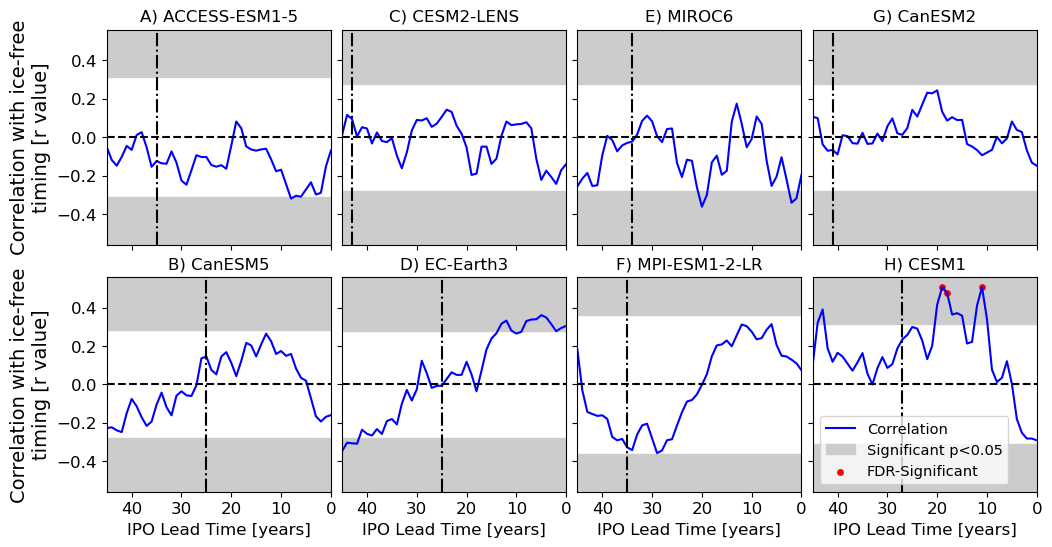

In [11]:
letter_list = ['A','B','C','D','E','F','G','H']

fig, ax = plt.subplots(2,4,figsize=[12,6])

for model_i, model_name in enumerate(['ACCESS-ESM1-5',
     'CanESM5', 'CESM2-LENS', 'EC-Earth3', 'MIROC6', 'MPI-ESM1-2-LR',
     'CanESM2', 'CESM1']):
    
    ax_x = int(model_i%2)
    ax_y = int(np.floor(model_i/2))

    # ax[ax_x][ax_y].plot(yr_range, r_val_dict[model_name],color='r', label='First Ice-Free Year')     
    ax[ax_x][ax_y].plot(yr_range, r_val_mean_dict[model_name],color='b', label='Correlation')     
    
    #now, instead shade in gray where significant 
    ax[ax_x][ax_y].fill_between(
        [-50,50],[r_critical_dict[model_name],r_critical_dict[model_name]],[9,9],color='0.8', label='Significant p<0.05')
    ax[ax_x][ax_y].fill_between(
        [-50,50],[-1*r_critical_dict[model_name],-1*r_critical_dict[model_name]],[-9,-9],color='0.8')
            
    ax[ax_x][ax_y].set_ylim(-0.56,0.56)
    ax[ax_x][ax_y].set_xlim(1,45)        
            
    ax[ax_x][ax_y].axhline(0, c='k',linestyle='--')
    ax[ax_x][ax_y].axvline(ens_IF[model_name], c='k',linestyle='-.')
    ax[ax_x][ax_y].set_title(model_name, fontsize=16);

    #plot the points that pass the Benjamini-Hochberg FDR for CESM1
    if model_name == 'CESM1':
        ax[ax_x][ax_y].scatter([yr_range[i] for i in (11,18,19)], 
                               [r_val_mean_dict[model_name][i] for i in (11,18,19)], 
                               c='r', s=15, label='FDR-Significant')
    
    if model_i < 2:
        ax[ax_x][ax_y].set_ylabel('Correlation with ice-free'+'\n'+'timing [r value]', fontsize=14)
    else:
        ax[ax_x][ax_y].set_yticklabels([])
    
    if model_i in [1,3,5,7]:
        ax[ax_x][ax_y].set_xlabel('IPO Lead Time [years]', fontsize=12)
        ax[ax_x][ax_y].set_xticks([40,30,20,10,0])
    else:
        ax[ax_x][ax_y].set_xlabel([])
        ax[ax_x][ax_y].set_xticks([40,30,20,10,0])
        ax[ax_x][ax_y].set_xticklabels([])
        ax[ax_x][ax_y].xaxis.label.set_color('1')
    
    ax[ax_x][ax_y].set_title(letter_list[model_i]+') '+model_name, fontsize=12)
    ax[ax_x][ax_y].invert_xaxis()
    ax[ax_x][ax_y].tick_params(axis='both', which='major', labelsize=12)


plt.subplots_adjust(wspace=0.05, hspace=0.15)

#add legend
ax[1][3].legend(fontsize=10.5);
                    
# plt.savefig('/glade/work/cwpowell/ice-free/figures/Correlation_IF_IPO_with_FDR.pdf',
#             bbox_inches='tight')